# Task 29: Manual Grid Search for Decision Tree

## Objective
To tune Decision Tree hyperparameters using a manually implemented
grid search. Different combinations of maximum depth, split criterion,
and minimum samples per split will be evaluated without using GridSearchCV.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["target"].value_counts())

Dataset shape: (302, 14)
target
1    164
0    138
Name: count, dtype: int64


In [3]:
feature_columns = [
    col for col in df.select_dtypes(include=["number"]).columns
    if col != "target"
]

X = df[feature_columns].to_numpy(dtype=float)
y_original = df["target"].to_numpy()

classes = np.unique(y_original)

if len(classes) != 2:
    raise ValueError("This task expects a binary target.")

y = (y_original == classes[1]).astype(int)


def manual_stratified_split(X, y, train_ratio=0.8, random_seed=42):
    rng = np.random.default_rng(random_seed)

    train_indices = []
    test_indices = []

    for target_value in np.unique(y):
        indices = np.where(y == target_value)[0].copy()
        rng.shuffle(indices)

        split_index = int(len(indices) * train_ratio)

        train_indices.extend(indices[:split_index])
        test_indices.extend(indices[split_index:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


X_train, X_test, y_train, y_test = manual_stratified_split(X, y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (241, 13)
Testing shape: (61, 13)


## Manual Grid Search

The algorithm tests combinations of:
- Maximum tree depth
- Split criterion: Gini or entropy
- Minimum samples required to split a node

Each configuration is evaluated using validation data. The best
configuration is selected based on validation accuracy.

In [4]:
def manual_gini(y_values):
    if len(y_values) == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    impurity = 1.0

    for count in counts.values():
        probability = count / len(y_values)
        impurity -= probability ** 2

    return impurity


def manual_entropy(y_values):
    if len(y_values) == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    entropy = 0.0

    for count in counts.values():
        probability = count / len(y_values)
        entropy -= probability * np.log2(probability)

    return entropy

In [5]:
def find_best_split(X, y, criterion="gini", min_samples_split=10):
    n_samples, n_features = X.shape

    if n_samples < min_samples_split:
        return None

    impurity_function = (
        manual_gini if criterion == "gini" else manual_entropy
    )

    parent_impurity = impurity_function(y)
    best_gain = 0
    best_split = None

    for feature_index in range(n_features):
        unique_values = np.unique(X[:, feature_index])

        if len(unique_values) < 2:
            continue

        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_split = {
                    "feature_index": feature_index,
                    "threshold": float(threshold),
                    "gain": float(gain),
                    "left_mask": left_mask,
                    "right_mask": right_mask
                }

    return best_split

In [6]:
def build_tree(
    X, y, feature_names,
    depth=0, max_depth=4,
    min_samples_split=10, criterion="gini"
):
    labels, counts = np.unique(y, return_counts=True)
    majority_class = int(labels[np.argmax(counts)])

    if (
        len(labels) == 1
        or depth >= max_depth
        or len(y) < min_samples_split
    ):
        return {"leaf": True, "prediction": majority_class}

    split = find_best_split(
        X, y,
        criterion=criterion,
        min_samples_split=min_samples_split
    )

    if split is None or split["gain"] <= 0:
        return {"leaf": True, "prediction": majority_class}

    left_mask = split["left_mask"]
    right_mask = split["right_mask"]

    return {
        "leaf": False,
        "feature_index": split["feature_index"],
        "threshold": split["threshold"],
        "feature": feature_names[split["feature_index"]],
        "left": build_tree(
            X[left_mask], y[left_mask], feature_names,
            depth + 1, max_depth, min_samples_split, criterion
        ),
        "right": build_tree(
            X[right_mask], y[right_mask], feature_names,
            depth + 1, max_depth, min_samples_split, criterion
        )
    }

In [7]:
def predict_one(node, row):
    if node["leaf"]:
        return node["prediction"]

    if row[node["feature_index"]] <= node["threshold"]:
        return predict_one(node["left"], row)

    return predict_one(node["right"], row)


def predict_tree(tree, X):
    return np.array([predict_one(tree, row) for row in X])


def manual_accuracy(y_true, y_pred):
    if len(y_true) == 0:
        return 0

    correct = sum(
        1 for actual, predicted in zip(y_true, y_pred)
        if actual == predicted
    )

    return correct / len(y_true)

In [8]:
X_subtrain, X_validation, y_subtrain, y_validation = (
    manual_stratified_split(
        X_train, y_train,
        train_ratio=0.8,
        random_seed=21
    )
)

print("Subtraining set:", X_subtrain.shape)
print("Validation set:", X_validation.shape)

Subtraining set: (192, 13)
Validation set: (49, 13)


In [9]:
depth_options = [2, 3, 4, 5]
criterion_options = ["gini", "entropy"]
min_samples_options = [5, 10, 20]

grid_results = []
best_score = -1
best_params = None
best_tree = None

for depth in depth_options:
    for criterion in criterion_options:
        for min_samples in min_samples_options:

            candidate_tree = build_tree(
                X_subtrain,
                y_subtrain,
                feature_columns,
                max_depth=depth,
                min_samples_split=min_samples,
                criterion=criterion
            )

            validation_predictions = predict_tree(
                candidate_tree,
                X_validation
            )

            score = manual_accuracy(
                y_validation,
                validation_predictions
            )

            grid_results.append({
                "max_depth": depth,
                "criterion": criterion,
                "min_samples_split": min_samples,
                "validation_accuracy": score
            })

            print(
                f"Depth={depth}, Criterion={criterion}, "
                f"Min Samples={min_samples}, "
                f"Validation Accuracy={score:.4f}"
            )

            if score > best_score:
                best_score = score
                best_params = {
                    "max_depth": depth,
                    "criterion": criterion,
                    "min_samples_split": min_samples
                }
                best_tree = candidate_tree

grid_df = pd.DataFrame(grid_results)

print("\nBest parameters:", best_params)
print("Best validation accuracy:", round(best_score, 4))

Depth=2, Criterion=gini, Min Samples=5, Validation Accuracy=0.7347
Depth=2, Criterion=gini, Min Samples=10, Validation Accuracy=0.7347
Depth=2, Criterion=gini, Min Samples=20, Validation Accuracy=0.7347
Depth=2, Criterion=entropy, Min Samples=5, Validation Accuracy=0.7347
Depth=2, Criterion=entropy, Min Samples=10, Validation Accuracy=0.7347
Depth=2, Criterion=entropy, Min Samples=20, Validation Accuracy=0.7347
Depth=3, Criterion=gini, Min Samples=5, Validation Accuracy=0.7959
Depth=3, Criterion=gini, Min Samples=10, Validation Accuracy=0.7959
Depth=3, Criterion=gini, Min Samples=20, Validation Accuracy=0.7959
Depth=3, Criterion=entropy, Min Samples=5, Validation Accuracy=0.7959
Depth=3, Criterion=entropy, Min Samples=10, Validation Accuracy=0.7959
Depth=3, Criterion=entropy, Min Samples=20, Validation Accuracy=0.7959
Depth=4, Criterion=gini, Min Samples=5, Validation Accuracy=0.7755
Depth=4, Criterion=gini, Min Samples=10, Validation Accuracy=0.7755
Depth=4, Criterion=gini, Min Sample

 max_depth criterion  min_samples_split  validation_accuracy
         3      gini                  5             0.795918
         3      gini                 10             0.795918
         4      gini                 20             0.795918
         4   entropy                  5             0.795918
         3   entropy                 20             0.795918
         3   entropy                 10             0.795918
         3   entropy                  5             0.795918
         3      gini                 20             0.795918
         5   entropy                 20             0.795918
         5      gini                 20             0.795918


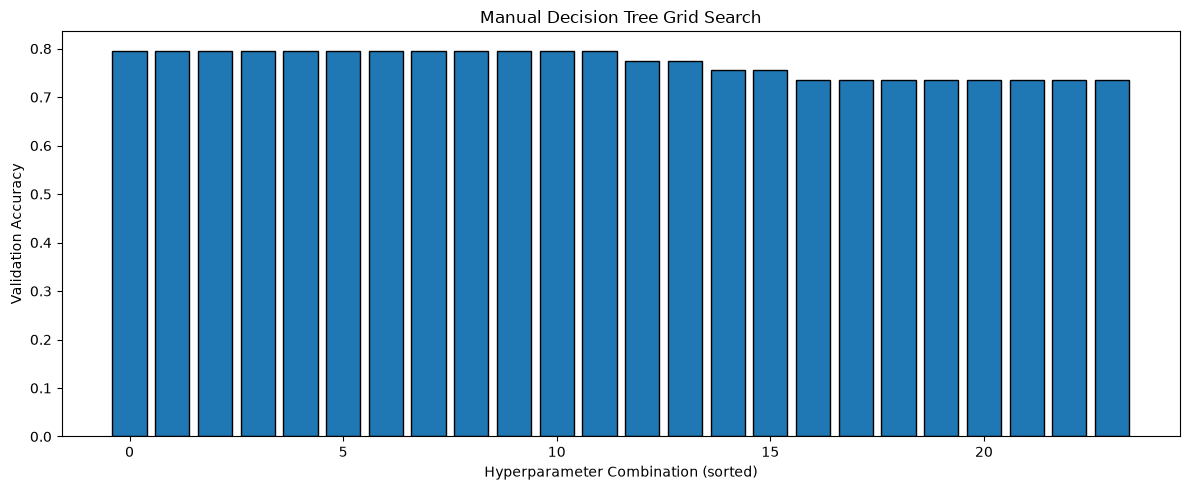

In [10]:
grid_df = grid_df.sort_values(
    by="validation_accuracy",
    ascending=False
).reset_index(drop=True)

print(grid_df.head(10).to_string(index=False))

plt.figure(figsize=(12, 5))

plt.bar(
    range(len(grid_df)),
    grid_df["validation_accuracy"],
    edgecolor="black"
)

plt.xlabel("Hyperparameter Combination (sorted)")
plt.ylabel("Validation Accuracy")
plt.title("Manual Decision Tree Grid Search")
plt.tight_layout()
plt.show()

In [11]:
final_tree = build_tree(
    X_train,
    y_train,
    feature_columns,
    max_depth=best_params["max_depth"],
    min_samples_split=best_params["min_samples_split"],
    criterion=best_params["criterion"]
)

test_predictions = predict_tree(final_tree, X_test)
test_accuracy = manual_accuracy(y_test, test_predictions)

print("Best parameters:", best_params)
print(f"Final test accuracy: {test_accuracy:.4f}")

Best parameters: {'max_depth': 3, 'criterion': 'gini', 'min_samples_split': 5}
Final test accuracy: 0.7705


## Conclusion

A manual grid search was implemented to compare Decision Tree
configurations using different maximum depths, split criteria, and
minimum sample thresholds. Validation accuracy was used to select
the best configuration, which was then evaluated on held-out test data.

The best configuration depends on the training and validation samples.
Validation accuracy can vary across splits, so the selected parameters
should not be interpreted as universally optimal.